In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

iris=load_iris()

X=iris.data
y=iris.target

print("Dataset Shape:",X.shape)
print("Target Shape:",y.shape)
print("Classes:",iris.target_names)
print("First 5 Features:")
print(X[:5])
print("First 5 Targets:")
print(y[:5])

Dataset Shape: (150, 4)
Target Shape: (150,)
Classes: ['setosa' 'versicolor' 'virginica']
First 5 Features:
[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
First 5 Targets:
[0 0 0 0 0]


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

scaler=StandardScaler()

X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

print("Training Samples:",len(X_train))
print("Testing Samples:",len(X_test))
print("Training Shape:",X_train.shape)
print("Testing Shape:",X_test.shape)

Training Samples: 120
Testing Samples: 30
Training Shape: (120, 4)
Testing Shape: (30, 4)


In [3]:
model=tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(16,activation="relu"),
    tf.keras.layers.Dense(8,activation="relu"),
    tf.keras.layers.Dense(3,activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

Model compiled successfully


In [5]:
history=model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

print("Training completed")

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.2292 - loss: 1.3081 - val_accuracy: 0.3333 - val_loss: 1.2110
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2917 - loss: 1.2574 - val_accuracy: 0.2917 - val_loss: 1.1817
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3750 - loss: 1.2157 - val_accuracy: 0.3333 - val_loss: 1.1562
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3750 - loss: 1.1814 - val_accuracy: 0.3333 - val_loss: 1.1340
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3958 - loss: 1.1449 - val_accuracy: 0.2917 - val_loss: 1.1085
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3958 - loss: 1.1033 - val_accuracy: 0.3333 - val_loss: 1.0812
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5521 - loss: 1.0625 - val_accuracy: 0.5000 - val_loss: 1.0490
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6458 - loss: 1.0233 - val_accuracy: 0.5417 - v

In [6]:
history=model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8854 - loss: 0.2380 - val_accuracy: 0.9167 - val_loss: 0.2602
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9271 - loss: 0.2349 - val_accuracy: 0.9167 - val_loss: 0.2547
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9167 - loss: 0.2311 - val_accuracy: 0.9167 - val_loss: 0.2531
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9062 - loss: 0.2285 - val_accuracy: 0.9167 - val_loss: 0.2478
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9271 - loss: 0.2243 - val_accuracy: 0.9167 - val_loss: 0.2410
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9271 - loss: 0.2206 - val_accuracy: 0.9167 - val_loss: 0.2318
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9271 - loss: 0.2173 - val_accuracy: 0.9167 - val_loss: 0.2267
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9271 - loss: 0.2129 - val_accuracy: 0.9167 - v

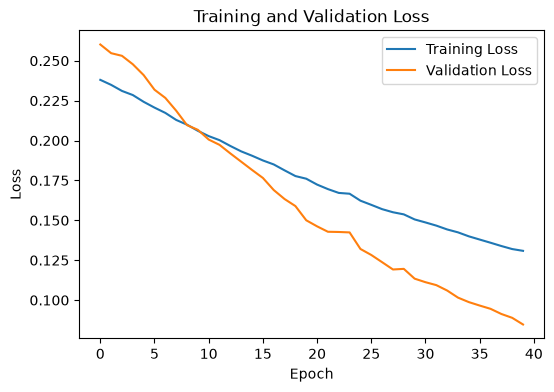

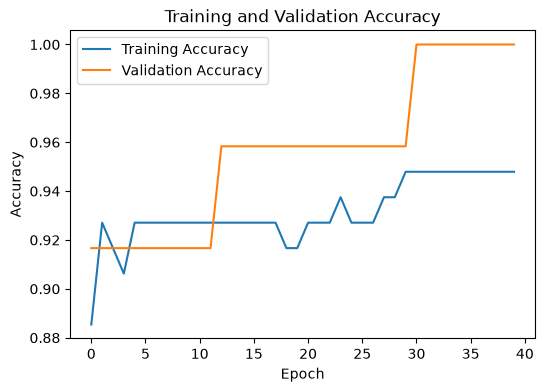

In [7]:
plt.figure(figsize=(6,4))
plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

In [8]:
loss,accuracy=model.evaluate(X_test,y_test,verbose=0)

print("Test Loss:",round(loss,4))
print("Test Accuracy:",round(accuracy,4))
print("Test Accuracy (%):",round(accuracy*100,2))

Test Loss: 0.1876
Test Accuracy: 0.9
Test Accuracy (%): 90.0


Actual Labels:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Labels:
[0 2 1 1 0 2 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]

Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  1  9]]


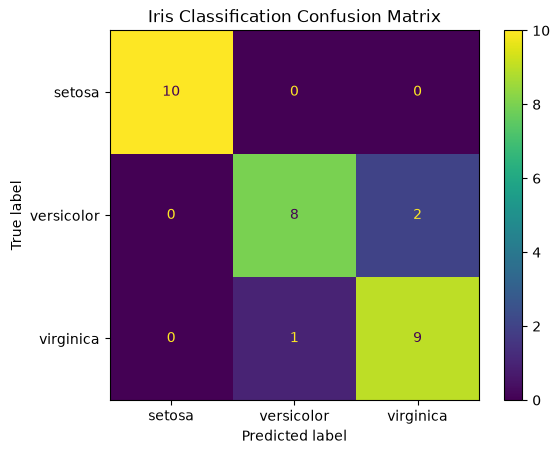

In [9]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

y_prob=model.predict(X_test,verbose=0)
y_pred=np.argmax(y_prob,axis=1)

print("Actual Labels:")
print(y_test)

print("\nPredicted Labels:")
print(y_pred)

cm=confusion_matrix(y_test,y_pred)

print("\nConfusion Matrix:")
print(cm)

disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()
plt.title("Iris Classification Confusion Matrix")
plt.show()

In [10]:
new_flower=np.array([[5.1,3.5,1.4,0.2]])

new_flower_scaled=scaler.transform(new_flower)

prediction=model.predict(new_flower_scaled,verbose=0)

class_index=np.argmax(prediction[0])
class_name=iris.target_names[class_index]

print("Predicted Class:",class_name)
print("Probabilities:",np.round(prediction[0],3))

Predicted Class: setosa
Probabilities: [1. 0. 0.]


In [13]:
import tensorflow as tf

loaded_model=tf.keras.models.load_model("iris_neural_network.keras")

print("Model loaded successfully")
loaded_model.summary()

Model loaded successfully


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 731 (2.86 KB)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 488 (1.91 KB)

In [14]:
new_flower=np.array([[6.1,2.8,4.7,1.2]])

new_flower_scaled=scaler.transform(new_flower)

prediction=loaded_model.predict(new_flower_scaled,verbose=0)

class_index=np.argmax(prediction[0])
class_name=iris.target_names[class_index]

print("Predicted Class:",class_name)
print("Probabilities:",np.round(prediction[0],3))

Predicted Class: versicolor
Probabilities: [0.01  0.895 0.095]


In [15]:
print("===== IRIS CLASSIFICATION RESULTS =====")
print("Dataset Samples:",len(X))
print("Training Samples:",len(X_train))
print("Testing Samples:",len(X_test))
print("Test Accuracy:",round(accuracy*100,2),"%")
print("Test Loss:",round(loss,4))
print("Model File: iris_neural_network.keras")
print("Classes:",list(iris.target_names))
print("======================================")

===== IRIS CLASSIFICATION RESULTS =====
Dataset Samples: 150
Training Samples: 120
Testing Samples: 30
Test Accuracy: 90.0 %
Test Loss: 0.1876
Model File: iris_neural_network.keras
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
